# ResNet-50 — Entraînement Distribué — CIFAR-10
## Projet : Systèmes Distribués et Intelligence Artificielle

**Objectif** : Comprendre comment PyTorch gère la distribution des calculs pour accélérer l'entraînement d'un modèle de Deep Learning.

### Plan en 7 étapes
| Étape | Description | Config |
|-------|-------------|--------|
| 1 | Préparation de l'environnement | |
| 2 | Chargement et distribution du dataset CIFAR-10 |  |
| 3 | Définition du modèle ResNet-50 | |
| 4 | Entraînement sur **CPU** | **Config A** |
| 5 | Entraînement sur **1 GPU** | **Config B** |
| 6 | Entraînement **DataParallel** (distribué) | **Config C** |
| 7 | **Comparaison et Visualisation** | A vs B vs C |



>  **Avant de lancer** : Exécution → Modifier le type d'exécution → GPU T4

---
## Imports

In [42]:
import os
import time
import copy
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torch.utils.data import DataLoader, Subset
from torch.utils.data.distributed import DistributedSampler
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

print('Imports OK')

Imports OK


---
## Étape 1 — Préparation de l'environnement

Vérification des GPUs disponibles et configuration du device principal.

In [43]:
print('   ÉTAPE 1 — Préparation de l\'environnement')
print('=' * 65)
print(f'PyTorch version  : {torch.__version__}')
print(f'CUDA disponible  : {torch.cuda.is_available()}')
print(f'Nombre de GPU    : {torch.cuda.device_count()}')

NUM_GPU = torch.cuda.device_count()

for i in range(NUM_GPU):
    p = torch.cuda.get_device_properties(i)
    print(f'  GPU {i} : {p.name} — {p.total_memory/1e9:.1f} GB VRAM')

# On limite à 2 GPU maximum (DataParallel)
NUM_GPU = min(NUM_GPU, 2)
print(f'\nGPU utilisés pour le distribué : {NUM_GPU}')


   ÉTAPE 1 — Préparation de l'environnement
PyTorch version  : 2.10.0+cu128
CUDA disponible  : True
Nombre de GPU    : 2
  GPU 0 : Tesla T4 — 15.6 GB VRAM
  GPU 1 : Tesla T4 — 15.6 GB VRAM

GPU utilisés pour le distribué : 2


---
## 2. Exploration des données

Chargement brut du dataset CIFAR-10 pour explorer sa structure avant toute transformation.

In [45]:
# Définition de DATA_DIR si pas encore défini
import os
DATA_DIR = '/kaggle/working/data'
os.makedirs(DATA_DIR, exist_ok=True)

# Charger les données brutes (sans transform) pour exploration
train_data_raw = torchvision.datasets.CIFAR10(root=DATA_DIR, train=True, download=True)
test_data_raw  = torchvision.datasets.CIFAR10(root=DATA_DIR, train=False, download=True)

In [46]:
# Récupérer les noms des classes
classes_names = train_data_raw.classes
print(f'Nombre de classes : {len(classes_names)}')
print(f'Classes : {classes_names}')

Nombre de classes : 10
Classes : ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [48]:
# Prendre la première image et afficher ses infos
image_raw, label_raw = train_data_raw[0]
print(f'Image : {image_raw.size}')
print(f'Label : {label_raw} ({classes_names[label_raw]})')
print(f'Type  : {type(image_raw)}')

Image : (32, 32)
Label : 6 (frog)
Type  : <class 'PIL.Image.Image'>


---
## 3. Visualisation des données

Affichage des images brutes (PIL) pour comprendre le dataset avant transformation.

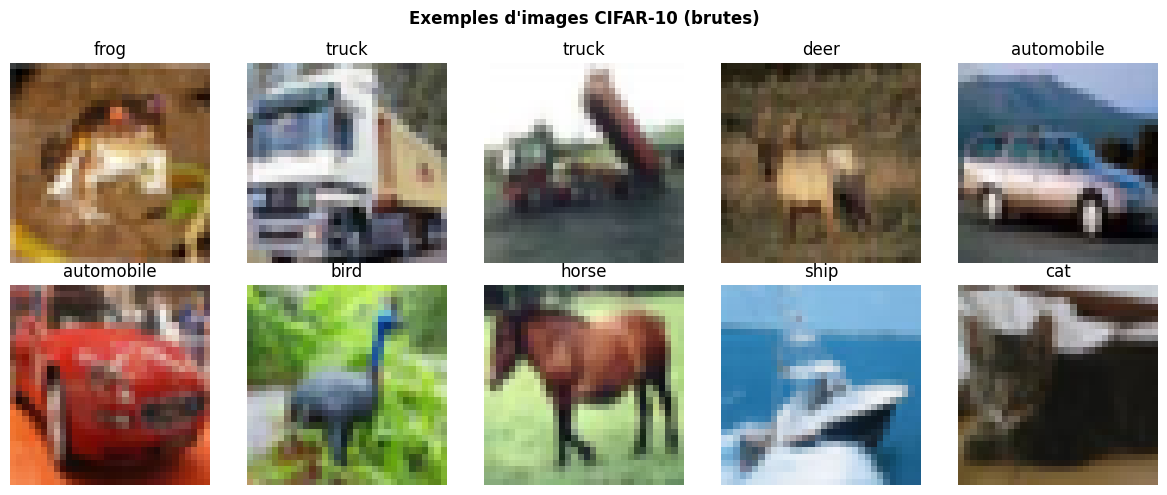

In [49]:
# Afficher 10 images avec leurs noms
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    img_v, lbl_v = train_data_raw[i]
    ax.imshow(img_v)
    ax.set_title(classes_names[lbl_v])
    ax.axis('off')

plt.suptitle("Exemples d'images CIFAR-10 (brutes)", fontweight='bold')
plt.tight_layout()
plt.show()

---
## Étape 2 — Chargement et distribution du dataset CIFAR-10

### Concept clé : DistributedSampler

Dans un vrai système distribué (DDP multi-processus), `DistributedSampler` découpe le dataset entre les workers pour éviter que deux processus lisent les mêmes images :

```
Dataset CIFAR-10 (50 000 images)
         |
   DistributedSampler
    /              \
Worker 0        Worker 1
images paires   images impaires
(25 000)        (25 000)
```

Avec `DataParallel` (mono-processus), le split est géré en interne par PyTorch (scatter), donc `DistributedSampler` n'est pas strictement requis on l'illustre ici pour la compréhension pédagogique.

In [50]:
# ── Hyperparamètres ─────────────────────────────────────────
BATCH_SIZE  = 256
NUM_EPOCHS  = 4
NUM_WORKERS = 2
SUBSET      = 10000   #  UN SEUL paramètre pour les 3 configs
DATA_DIR    = '/kaggle/working/data'

# ── Transforms ──────────────────────────────────────────────
transform_train = transforms.Compose([
    transforms.Resize(224),
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(224, padding=8),
    transforms.ColorJitter(brightness=0.2, contrast=0.2,
                           saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465),
                         std =(0.2023, 0.1994, 0.2010)),
])
transform_test = transforms.Compose([
    transforms.Resize(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.4914, 0.4822, 0.4465),
                         std =(0.2023, 0.1994, 0.2010)),
])

# ── Téléchargement CIFAR-10 ──────────────────────────────────
print('Téléchargement CIFAR-10')
train_dataset_full = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=True,  download=True, transform=transform_train
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=transform_test
)

#  UN SEUL subset partagé par les 3 configs
subset_data = Subset(train_dataset_full, indices=range(SUBSET))

# ── DataLoaders ──────────────────────────────────────────────
# Config A — CPU (batch plus petit car CPU)
loader_cpu = DataLoader(
    subset_data, batch_size=32, shuffle=True,    #  subset_data
    num_workers=0, pin_memory=False
)
# Config B — 1 GPU
loader_gpu = DataLoader(
    subset_data, batch_size=BATCH_SIZE, shuffle=True,   #  subset_data
    num_workers=NUM_WORKERS, pin_memory=True
)
# Config C — DataParallel
loader_dp = DataLoader(
    subset_data, batch_size=BATCH_SIZE, shuffle=True,   #  subset_data
    num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=True
)
loader_test = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True
)

CLASSES = ('avion', 'auto', 'oiseau', 'chat', 'cerf',
           'chien', 'grenouille', 'cheval', 'bateau', 'camion')

print(f'Subset (3 configs) : {SUBSET:,} images')    #  même ligne pour tout
print(f'Test               : {len(test_dataset):,} images')
print(f'Batch size         : {BATCH_SIZE} total / {BATCH_SIZE // max(NUM_GPU,1)} par GPU')
print(f'Résolution         : 224×224 (format ImageNet)')

Téléchargement CIFAR-10
Subset (3 configs) : 10,000 images
Test               : 10,000 images
Batch size         : 256 total / 128 par GPU
Résolution         : 224×224 (format ImageNet)


### Illustration du DistributedSampler

In [51]:
# Illustration pédagogique du DistributedSampler
if NUM_GPU >= 1:
    sampler_example = DistributedSampler(
        train_dataset_full,
        num_replicas=max(NUM_GPU, 1),
        rank=0,
        shuffle=True
    )
    print('DistributedSampler — Simulation')
    print(f'  num_replicas (nb workers) : {sampler_example.num_replicas}')
    print(f'  rank (ce processus)       : {sampler_example.rank}')
    print(f'  Images assignées/worker   : {len(sampler_example):,}')
    print(f'  → Worker 0 : images 0, 2, 4, ... (indices pairs)')
    print(f'  → Worker 1 : images 1, 3, 5, ... (indices impairs)')
    print('  (DataParallel gère le split en interne via scatter)')

DistributedSampler — Simulation
  num_replicas (nb workers) : 2
  rank (ce processus)       : 0
  Images assignées/worker   : 25,000
  → Worker 0 : images 0, 2, 4, ... (indices pairs)
  → Worker 1 : images 1, 3, 5, ... (indices impairs)
  (DataParallel gère le split en interne via scatter)


---
## Étape 3 — Définition du modèle ResNet-50

### Architecture fine-tuning différencié

```
ResNet-50 pré-entraîné (ImageNet)
├── conv1 + bn1 + relu + maxpool   
├── layer1 + layer2                
├── layer3 + layer4                
└── fc (remplacée)
       Dropout(0.4)
       Linear(2048 → 256)
       ReLU
       Dropout(0.3)
       Linear(256 → 10)  ← 10 classes CIFAR-10
```


In [52]:
def build_model():
    """
    Construit un ResNet-50 pré-entraîné adapté à CIFAR-10.
    Toutes les couches sont dégelées pour une vraie parallélisation.
    """
    model = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)

    # Adapter la tête pour CIFAR-10 (10 classes)
    num_features = model.fc.in_features  # 2048
    model.fc = nn.Sequential(
        nn.Dropout(0.4),
        nn.Linear(num_features, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.3),
        nn.Linear(256, 10)  # 10 classes CIFAR-10
    )

    #  Dégeler TOUTES les couches
    # (layer1+layer2 gelés → GPU secondaire sans gradients → inutile)
    for param in model.parameters():
        param.requires_grad = True

    return model


def build_optimizer(model):
    base  = model.module if isinstance(model, nn.DataParallel) else model
    named = list(base.named_parameters())

    return optim.AdamW([
        {'params': [p for n, p in named
                    if any(x in n for x in ['layer1', 'layer2'])
                    and p.requires_grad],
         'lr': 5e-6, 'weight_decay': 1e-4},   # ← réduit

        {'params': [p for n, p in named
                    if any(x in n for x in ['layer3', 'layer4'])
                    and p.requires_grad],
         'lr': 5e-5, 'weight_decay': 1e-4},   # ← réduit

        {'params': [p for n, p in named
                    if 'fc' in n and p.requires_grad],
         'lr': 1e-4, 'weight_decay': 1e-3},   # ← réduit
    ])


# Statistiques
model_ref = build_model()
params_total     = sum(p.numel() for p in model_ref.parameters())
params_trainable = sum(p.numel() for p in model_ref.parameters()
                       if p.requires_grad)
print(f'Modèle               : ResNet-50 (poids ImageNet)')
print(f'Paramètres totaux    : {params_total:,}')
print(f'Paramètres entraînés : {params_trainable:,}  (toutes couches dégelées)')
print(f'Tête fc              : Dropout→Linear(2048,256)→ReLU→Dropout→Linear(256,10)')
del model_ref

Modèle               : ResNet-50 (poids ImageNet)
Paramètres totaux    : 24,035,146
Paramètres entraînés : 24,035,146  (toutes couches dégelées)
Tête fc              : Dropout→Linear(2048,256)→ReLU→Dropout→Linear(256,10)


---
## Fonctions d'entraînement communes

Ces fonctions sont partagées par les 3 configurations :
- `train_one_epoch` : une epoch avec AMP optionnel
- `evaluate` : validation sur le test set
- `run_training` : boucle complète, retourne l'historique

In [53]:
def train_one_epoch(model, loader, optimizer, criterion, scaler, device,
                    use_amp=True, config_name=''):
    """Entraîne le modèle pour une epoch. Retourne (loss_moy, accuracy%)."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for i, (imgs, lbls) in enumerate(loader):
        imgs = imgs.to(device, non_blocking=True)
        lbls = lbls.to(device, non_blocking=True)
        optimizer.zero_grad()

        if use_amp and device.type == 'cuda':
            with torch.amp.autocast('cuda'):
                out  = model(imgs)
                loss = criterion(out, lbls)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            out  = model(imgs)
            loss = criterion(out, lbls)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

        total_loss += loss.item()
        correct    += out.max(1)[1].eq(lbls).sum().item()
        total      += lbls.size(0)

        if (i + 1) % 100 == 0:
            print(f'    [{config_name}] Batch {i+1:4d}/{len(loader)} | '
                  f'Loss {total_loss/(i+1):.4f} | '
                  f'Acc {100*correct/total:.1f}%')

    return total_loss / len(loader), 100 * correct / total


def evaluate(model, loader, criterion, device):
    """Évalue le modèle sur loader. Retourne (loss, accuracy%)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            if device.type == 'cuda':
                with torch.amp.autocast('cuda'):
                    out  = model(imgs)
                    loss = criterion(out, lbls)
            else:
                out  = model(imgs)
                loss = criterion(out, lbls)
            total_loss += loss.item()
            correct    += out.max(1)[1].eq(lbls).sum().item()
            total      += lbls.size(0)
    return total_loss / len(loader), 100 * correct / total


def run_training(config_name, model, loader, test_loader,
                 device, num_epochs, use_amp=True):
    """Lance l'entraînement complet pour une configuration. Retourne history."""
    print(f'\n{"-"*65}')
    print(f'  Configuration : {config_name}')
    print(f'  Device        : {device}')
    print(f'  Mixed Prec.   : {"Oui (float16)" if use_amp else "Non (float32)"}')
    if isinstance(model, nn.DataParallel):
        print(f'  DataParallel  : {len(model.device_ids)} GPU(s)')
    print(f'{"-"*65}')

    model     = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = build_optimizer(model)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-6
    )
    scaler = torch.amp.GradScaler('cuda') \
             if (use_amp and device.type == 'cuda') else None

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss':   [], 'val_acc':   [],
        'epoch_time': []
    }

    t_total = time.time()
    for epoch in range(num_epochs):
        print(f'\n  ── Epoch {epoch+1}/{num_epochs}')
        t0 = time.time()

        tr_loss, tr_acc = train_one_epoch(
            model, loader, optimizer, criterion,
            scaler, device, use_amp, config_name
        )
        vl_loss, vl_acc = evaluate(model, test_loader, criterion, device) \
                          if device.type == 'cuda' else (0.0, 0.0)

        scheduler.step()
        ep_t = time.time() - t0

        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(vl_loss)
        history['val_acc'].append(vl_acc)
        history['epoch_time'].append(ep_t)

        print(f'  → Loss:{tr_loss:.4f} | Train:{tr_acc:.1f}% | '
              f'Val:{vl_acc:.1f}% | Temps:{ep_t:.1f}s')

    history['total_time']   = time.time() - t_total
    history['mean_ep_time'] = float(np.mean(history['epoch_time']))

    print(f'\n  Terminé en {history["total_time"]/60:.1f} min '
          f'(moy. {history["mean_ep_time"]:.1f}s/epoch)')
    if device.type == 'cuda' and any(v > 0 for v in history['val_acc']):
        print(f'  Meilleure val acc : {max(history["val_acc"]):.2f}%')

    return history


print('Fonctions définies ')

Fonctions définies 


---
## Étape 4 — Config A : Entraînement sur CPU

Le CPU sert de **baseline de référence**. Il est intentionnellement plus lent.

Pour ne pas attendre trop longtemps, on utilise seulement **10 000 images**  et un batch de 32.



In [54]:
print(f'  loader_cpu : {len(loader_cpu.dataset)} images')
print(f'  loader_gpu : {len(loader_gpu.dataset)} images')
print(f'  loader_dp  : {len(loader_dp.dataset)} images')

  loader_cpu : 10000 images
  loader_gpu : 10000 images
  loader_dp  : 10000 images


In [18]:
print('=' * 65)
print('   ÉTAPE 4 — CONFIG A : Entraînement sur CPU (benchmark)')
print('=' * 65)
print(f'  Sous-ensemble : {SUBSET} images | batch=32 | {NUM_EPOCHS} epochs')

device_cpu = torch.device('cpu')
model_cpu  = build_model()

history_cpu = run_training(
    config_name = 'CPU',
    model       = model_cpu,
    loader      = loader_cpu,
    test_loader = loader_test,
    device      = device_cpu,
    num_epochs  = NUM_EPOCHS,
    use_amp     = False
)

del model_cpu
torch.cuda.empty_cache() if torch.cuda.is_available() else None
print('\n  Config A (CPU) terminée ')

   ÉTAPE 4 — CONFIG A : Entraînement sur CPU (benchmark)
  Sous-ensemble : 10000 images | batch=32 | 4 epochs

-----------------------------------------------------------------
  Configuration : CPU
  Device        : cpu
  Mixed Prec.   : Non (float32)
-----------------------------------------------------------------

  ── Epoch 1/4
    [CPU] Batch  100/313 | Loss 1.6279 | Acc 54.3%
    [CPU] Batch  200/313 | Loss 1.2785 | Acc 68.5%
    [CPU] Batch  300/313 | Loss 1.1384 | Acc 74.3%
  → Loss:1.1257 | Train:74.9% | Val:0.0% | Temps:2238.5s

  ── Epoch 2/4
    [CPU] Batch  100/313 | Loss 0.7666 | Acc 90.1%
    [CPU] Batch  200/313 | Loss 0.7554 | Acc 90.3%
    [CPU] Batch  300/313 | Loss 0.7494 | Acc 90.7%
  → Loss:0.7472 | Train:90.8% | Val:0.0% | Temps:2198.9s

  ── Epoch 3/4
    [CPU] Batch  100/313 | Loss 0.6697 | Acc 94.5%
    [CPU] Batch  200/313 | Loss 0.6595 | Acc 94.8%
    [CPU] Batch  300/313 | Loss 0.6555 | Acc 95.0%
  → Loss:0.6558 | Train:95.0% | Val:0.0% | Temps:2162.4s

  

In [21]:
print("Nombre total d'images :", len(loader_gpu.dataset))

Nombre total d'images : 10000


---
## Étape 5 — Config B : Entraînement sur 1 GPU

Un seul GPU avec **Mixed Precision (AMP)** en float16 :
- Calculs 2–3× plus rapides qu'en float32
- Mémoire réduite de moitié
- Dataset  : 10 000 images



In [55]:
print('=' * 65)
print(' ÉTAPE 5 — CONFIG B : Entraînement sur 1 GPU')
print('=' * 65)

if not torch.cuda.is_available():
    print(' Pas de GPU disponible — Config B ignorée')
    history_gpu = None
else:
    device_gpu = torch.device('cuda:0')
    model_gpu  = build_model()

    history_gpu = run_training(
        config_name = '1 GPU',
        model       = model_gpu,
        loader      = loader_gpu,
        test_loader = loader_test,
        device      = device_gpu,
        num_epochs  = NUM_EPOCHS,
        use_amp     = True
    )

    del model_gpu
    torch.cuda.empty_cache()
    print('\n  Config B (1 GPU) terminée ')

   ÉTAPE 5 — CONFIG B : Entraînement sur 1 GPU

-----------------------------------------------------------------
  Configuration : 1 GPU
  Device        : cuda:0
  Mixed Prec.   : Oui (float16)
-----------------------------------------------------------------

  ── Epoch 1/4
  → Loss:2.0422 | Train:38.4% | Val:71.0% | Temps:67.6s

  ── Epoch 2/4
  → Loss:1.2955 | Train:72.3% | Val:83.9% | Temps:66.6s

  ── Epoch 3/4
  → Loss:0.9980 | Train:81.8% | Val:87.1% | Temps:65.1s

  ── Epoch 4/4
  → Loss:0.9113 | Train:85.3% | Val:87.9% | Temps:64.9s

  Terminé en 4.4 min (moy. 66.0s/epoch)
  Meilleure val acc : 87.89%

  Config B (1 GPU) terminée 


---
## Étape 6 — Config C : Entraînement Distribué (DataParallel)

### Comment fonctionne DataParallel ?

Batch de 256 images     
        |
   1. SCATTER
   /           \
GPU 0          GPU 1
128 images     128 images  
   |
   2. REPLICATE (copie du modèle sur chaque GPU)
   |
   3. FORWARD (en parallèle sur chaque GPU)
   |
   4. GATHER (sorties réunies sur GPU 0 → loss)
   |
   5. BACKWARD + synchronisation des gradients
      → poids mis à jour de façon synchrone
```

**Pourquoi GPU1 dormait avant ?**
- Les couches `layer1` et `layer2` étaient gelées (`requires_grad=False`)
- Sans gradients à calculer sur ces couches, GPU1 n'avait presque rien à faire
- **Fix** : toutes les couches sont dégelées → GPU1 passe de 0.02 GB → 4–5 GB



In [56]:
print('=' * 65)
print(' ÉTAPE 6 — CONFIG C : Entraînement Distribué (DataParallel)')
print('=' * 65)

if not torch.cuda.is_available():
    print(' Pas de GPU disponible — Config C ignorée')
    history_dp = None
else:
    device_dp = torch.device('cuda')
    model_dp  = build_model()

    if NUM_GPU >= 2:
        model_dp = nn.DataParallel(model_dp, device_ids=list(range(NUM_GPU)))
        print(f'  DataParallel activé : {NUM_GPU} GPU(s) '
              f'→ {BATCH_SIZE // NUM_GPU} images/GPU')
    else:
        print('  1 seul GPU détecté — DataParallel non activé')

    history_dp = run_training(
        config_name = f'DataParallel ({NUM_GPU} GPU)',
        model       = model_dp,
        loader      = loader_dp,
        test_loader = loader_test,
        device      = device_dp,
        num_epochs  = NUM_EPOCHS,
        use_amp     = True
    )

    del model_dp
    torch.cuda.empty_cache()
    print('\n  Config C (DataParallel) terminée ')

   ÉTAPE 6 — CONFIG C : Entraînement Distribué (DataParallel)
  DataParallel activé : 2 GPU(s) → 128 images/GPU

-----------------------------------------------------------------
  Configuration : DataParallel (2 GPU)
  Device        : cuda
  Mixed Prec.   : Oui (float16)
  DataParallel  : 2 GPU(s)
-----------------------------------------------------------------

  ── Epoch 1/4
  → Loss:2.0626 | Train:38.2% | Val:67.5% | Temps:54.9s

  ── Epoch 2/4
  → Loss:1.3061 | Train:72.0% | Val:84.6% | Temps:54.3s

  ── Epoch 3/4
  → Loss:0.9847 | Train:82.9% | Val:87.7% | Temps:54.0s

  ── Epoch 4/4
  → Loss:0.9179 | Train:85.2% | Val:88.5% | Temps:54.3s

  Terminé en 3.6 min (moy. 54.4s/epoch)
  Meilleure val acc : 88.45%

  Config C (DataParallel) terminée 


---
## Étape 7 — Comparaison et Visualisation

Trois graphiques :
1. **Bar chart comparatif** A vs B vs C — temps par epoch + accélération ×CPU 
2. **Courbes Loss & Accuracy** — évolution sur les epochs
3. **Temps par epoch** — évolution au fil du temps

In [57]:
# ── Palette cohérente ────────────────────────────────────────
C_CPU = '#D85A30'   # orange-rouge → CPU
C_GPU = '#1D9E75'   # vert         → 1 GPU
C_DP  = '#7F77DD'   # violet       → DataParallel

configs = []
if history_cpu: configs.append(('CPU',                           history_cpu, C_CPU))
if history_gpu: configs.append(('1 GPU (AMP)',                   history_gpu, C_GPU))
if history_dp:  configs.append((f'DataParallel ({NUM_GPU} GPU)', history_dp,  C_DP))

epochs_x = range(1, NUM_EPOCHS + 1)
print(f'Configurations à comparer : {[c[0] for c in configs]}')

Configurations à comparer : ['CPU', '1 GPU (AMP)', 'DataParallel (2 GPU)']


###  Graphique 1 — Bar chart comparatif 

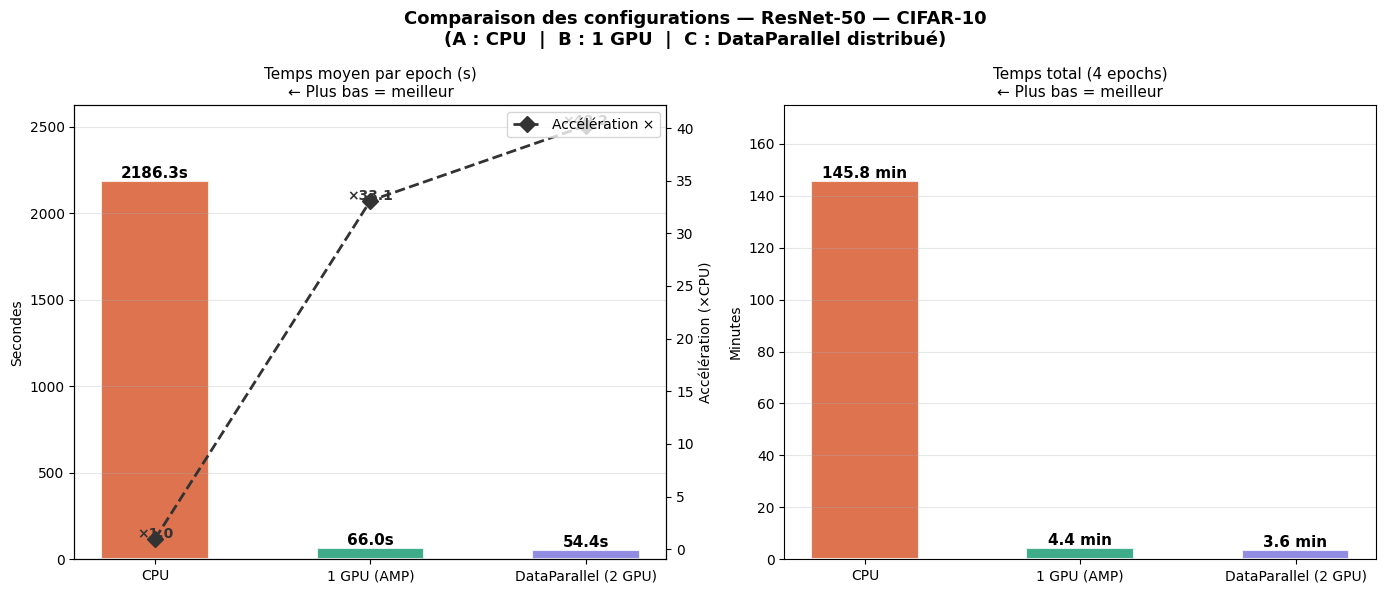

Sauvegardé : comparaison_configs.png 


In [58]:
fig1, axes1 = plt.subplots(1, 2, figsize=(14, 6))
fig1.suptitle(
    'Comparaison des configurations — ResNet-50 — CIFAR-10\n'
    '(A : CPU  |  B : 1 GPU  |  C : DataParallel distribué)',
    fontsize=13, fontweight='bold'
)

# ── Temps moyen par epoch ────────────────────────────────────
ax = axes1[0]
labels = [c[0] for c in configs]
means  = [c[1]['mean_ep_time'] for c in configs]
colors = [c[2] for c in configs]
bars   = ax.bar(labels, means, color=colors, alpha=0.85,
                edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, means):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.5,
            f'{val:.1f}s', ha='center', va='bottom',
            fontweight='bold', fontsize=11)
ax.set_title('Temps moyen par epoch (s)\n← Plus bas = meilleur', fontsize=11)
ax.set_ylabel('Secondes')
ax.set_ylim(0, max(means) * 1.2)
ax.grid(axis='y', alpha=0.3)

# Accélération relative (×CPU)
if len(means) > 1:
    ref      = means[0]
    speedups = [ref / m for m in means]
    ax2      = ax.twinx()
    ax2.plot(labels, speedups, 'D--', color='#333333',
             markersize=8, linewidth=2, label='Accélération ×')
    for i, sp in enumerate(speedups):
        ax2.text(i, sp + 0.05, f'×{sp:.1f}', ha='center',
                 fontsize=10, color='#333333', fontweight='bold')
    ax2.set_ylabel('Accélération (×CPU)')
    ax2.legend(loc='upper right')

# ── Temps total d'entraînement ───────────────────────────────
ax = axes1[1]
totals = [c[1]['total_time'] / 60 for c in configs]
bars   = ax.bar(labels, totals, color=colors, alpha=0.85,
                edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, totals):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.02,
            f'{val:.1f} min', ha='center', va='bottom',
            fontweight='bold', fontsize=11)
ax.set_title(f'Temps total ({NUM_EPOCHS} epochs)\n← Plus bas = meilleur', fontsize=11)
ax.set_ylabel('Minutes')
ax.set_ylim(0, max(totals) * 1.2)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/comparaison_configs.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : comparaison_configs.png ')

###  Graphique 2 — Courbes Loss & Accuracy

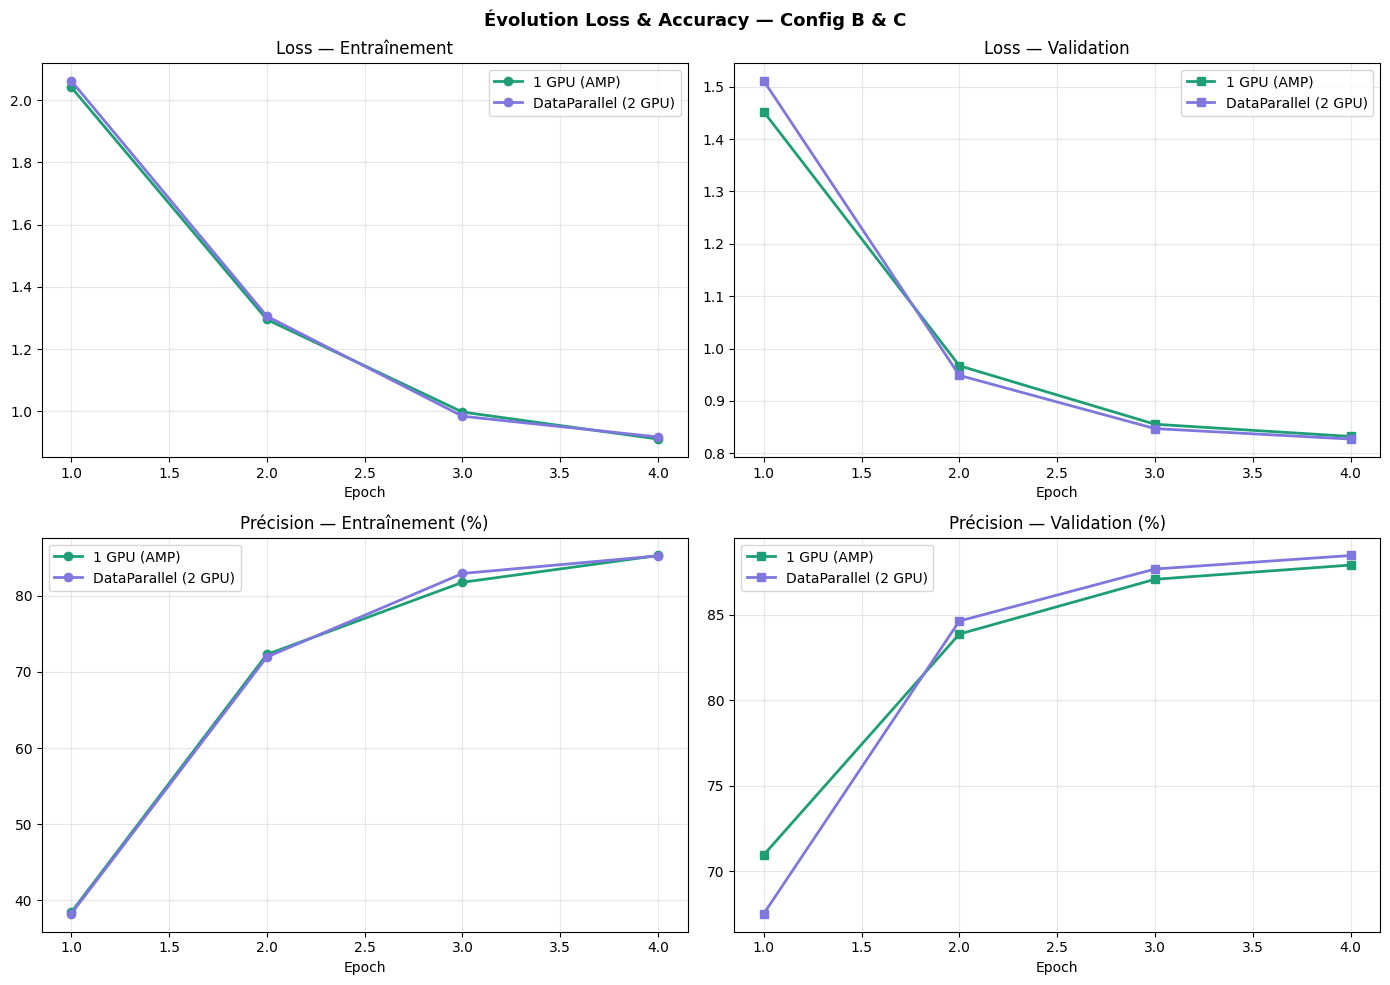

Sauvegardé : courbes_loss_acc.png 


In [59]:
fig2, axes2 = plt.subplots(2, 2, figsize=(14, 10))
fig2.suptitle('Évolution Loss & Accuracy — Config B & C',
              fontsize=13, fontweight='bold')

# Loss train
ax = axes2[0, 0]
for name, hist, col in configs:
    if hist['train_loss'] and name != 'CPU':
        ax.plot(epochs_x, hist['train_loss'],
                color=col, lw=2, marker='o', label=name)
ax.set_title('Loss — Entraînement')
ax.set_xlabel('Epoch')
ax.legend()
ax.grid(alpha=0.3)

# Loss val
ax = axes2[0, 1]
for name, hist, col in configs:
    if hist['val_loss'] and any(v > 0 for v in hist['val_loss']):
        ax.plot(epochs_x, hist['val_loss'],
                color=col, lw=2, marker='s', label=name)
ax.set_title('Loss — Validation')
ax.set_xlabel('Epoch')
ax.legend()
ax.grid(alpha=0.3)

# Accuracy train
ax = axes2[1, 0]
for name, hist, col in configs:
    if hist['train_acc'] and name != 'CPU':
        ax.plot(epochs_x, hist['train_acc'],
                color=col, lw=2, marker='o', label=name)
ax.set_title('Précision — Entraînement (%)')
ax.set_xlabel('Epoch')
ax.legend()
ax.grid(alpha=0.3)

# Accuracy val
ax = axes2[1, 1]
for name, hist, col in configs:
    if hist['val_acc'] and any(v > 0 for v in hist['val_acc']):
        ax.plot(epochs_x, hist['val_acc'],
                color=col, lw=2, marker='s', label=name)
ax.set_title('Précision — Validation (%)')
ax.set_xlabel('Epoch')
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/courbes_loss_acc.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : courbes_loss_acc.png ')

###  Graphique 3 — Temps par epoch

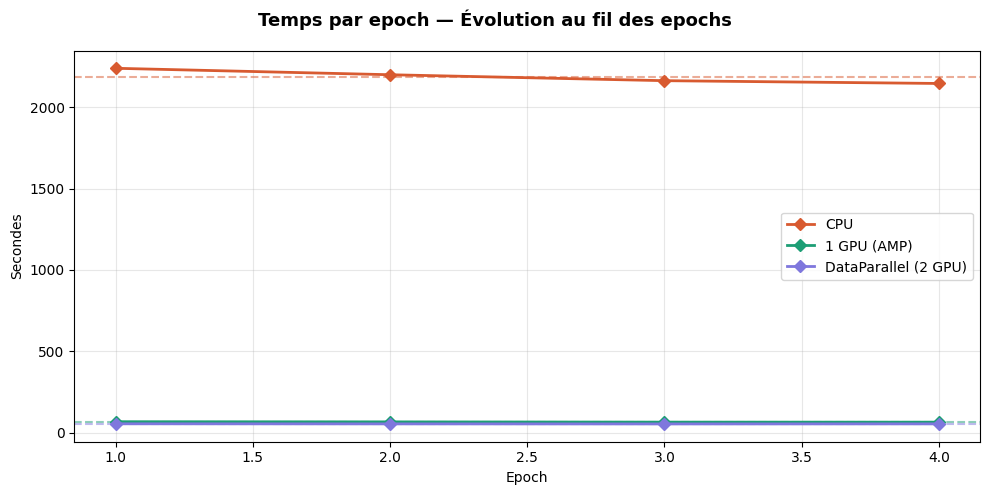

Sauvegardé : temps_par_epoch.png 


In [60]:
fig3, ax3 = plt.subplots(figsize=(10, 5))
fig3.suptitle('Temps par epoch — Évolution au fil des epochs',
              fontsize=13, fontweight='bold')

for name, hist, col in configs:
    ax3.plot(epochs_x, hist['epoch_time'],
             color=col, lw=2, marker='D', label=name)
    ax3.axhline(hist['mean_ep_time'], color=col,
                linestyle='--', alpha=0.5)

ax3.set_xlabel('Epoch')
ax3.set_ylabel('Secondes')
ax3.legend()
ax3.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/temps_par_epoch.png', dpi=150, bbox_inches='tight')
plt.show()
print('Sauvegardé : temps_par_epoch.png ')

---
## Rapport Final

Synthèse des résultats et sauvegarde des modèles.

In [62]:
print('\n' + '=' * 65)
print('        RAPPORT FINAL — ResNet-50 — CIFAR-10')
print('=' * 65)
print(f'{"Configuration":<30} {"Moy.epoch":>10} {"Total":>10} {"Val Acc":>10}')
print('─' * 65)
for name, hist, _ in configs:
    val_acc = f'{max(hist["val_acc"]):.2f}%' \
              if any(v > 0 for v in hist['val_acc']) else '—'
    print(f'  {name:<28} '
          f'{hist["mean_ep_time"]:>8.1f}s '
          f'{hist["total_time"]/60:>8.1f}m '
          f'{val_acc:>10}')

print()
if history_cpu and history_dp:
    sp = history_cpu['mean_ep_time'] / history_dp['mean_ep_time']
    print(f'  Accélération DataParallel vs CPU   : ×{sp:.1f}')
if history_gpu and history_dp:
    sp2 = history_gpu['mean_ep_time'] / history_dp['mean_ep_time']
    print(f'  Accélération DataParallel vs 1 GPU : ×{sp2:.2f}')

print('\n' + '=' * 65)
print('  Fichiers sauvegardés :')
print('    /kaggle/working/comparaison_configs.png  ← livrable principal')
print('    /kaggle/working/courbes_loss_acc.png')
print('    /kaggle/working/temps_par_epoch.png')
print('=' * 65)

# Sauvegarde des résultats
torch.save({
    'num_epochs'  : NUM_EPOCHS,
    'num_gpu'     : NUM_GPU,
    'history_cpu' : history_cpu,
    'history_gpu' : history_gpu,
    'history_dp'  : history_dp,
}, '/kaggle/working/resultats_complets.pth')
print('\n  Résultats sauvegardés : resultats_complets.pth ')


        RAPPORT FINAL — ResNet-50 — CIFAR-10
Configuration                   Moy.epoch      Total    Val Acc
─────────────────────────────────────────────────────────────────
  CPU                            2186.3s    145.8m          —
  1 GPU (AMP)                      66.0s      4.4m     87.89%
  DataParallel (2 GPU)             54.4s      3.6m     88.45%

  Accélération DataParallel vs CPU   : ×40.2
  Accélération DataParallel vs 1 GPU : ×1.21

  Fichiers sauvegardés :
    /kaggle/working/comparaison_configs.png  ← livrable principal
    /kaggle/working/courbes_loss_acc.png
    /kaggle/working/temps_par_epoch.png

  Résultats sauvegardés : resultats_complets.pth 
